# Explainability, Residual Diagnostics & Forecast Uncertainty

Inspect residuals and interval performance from genuine chronological holdout forecasts. Prophet trend and seasonal components are shown in Notebook 06. This notebook checks observed-versus-predicted values, residual mean and spread, residual autocorrelation, interval coverage, and interval width.


,restaurant,model,n,mae,rmse,wape,smape,mase,mean_error,r2,interval_coverage,interval_mean_width
0,Assa Frão,hist_gradient_boosting_recursive,28,10.662102,13.696934,0.297349,0.337980,0.563977,-1.665898,0.513318,NaN,NaN
1,Assa Frão,statsmodels_SARIMAX_weekly_AIC_selected_on_ali...,28,10.970242,14.978084,0.305943,0.340051,0.580277,-6.388294,0.418016,0.964286,73.140694
2,Assa Frão,tensorflow_mlp,28,11.455016,15.019550,0.319463,0.377599,0.605919,-6.064397,0.414789,NaN,NaN
3,Assa Frão,baseline_seasonal_naive_7,28,16.500000,20.617260,0.460159,0.509193,0.872776,1.285714,-0.102708,NaN,NaN
4,Assa Frão,baseline_naive,28,30.714286,34.314720,0.856574,0.683024,1.624648,28.142857,-2.054636,NaN,NaN
5,Chimi & Churri,prophet_additive_selected_on_aligned_cv,28,10.353776,12.762159,0.241588,0.268616,0.672639,-1.945099,0.582662,0.892857,38.000378
6,Chimi & Churri,tensorflow_gru,28,10.389546,13.881032,0.242423,0.267621,0.674962,-4.522789,0.506277,NaN,NaN
7,Chimi & Churri,hist_gradient_boosting_recursive,28,10.736188,14.727065,0.250511,0.276233,0.697482,-5.158750,0.444259,NaN,NaN
8,Chimi & Churri,baseline_seasonal_naive_7,28,15.142857,18.446835,0.353333,0.477107,0.983764,-3.142857,0.128066,NaN,NaN
9,Chimi & Churri,baseline_naive,28,52.285714,55.759688,1.220000,0.811387,3.396770,52.142857,-6.966742,NaN,NaN


Statsmodels Assa Frão residual mean/std: -3.724367486029697 17.994643394970776
Statsmodels Assa Frão holdout interval: {'coverage': 0.9642857142857143, 'mean_interval_width': 88.59767491712608}
Statsmodels Chimi & Churri residual mean/std: -3.880204135104949 16.682723961947183
Statsmodels Chimi & Churri holdout interval: {'coverage': 0.9523809523809523, 'mean_interval_width': 69.53800179548381}


Prophet Assa Frão residual mean/std: -3.9540806765325742 12.587945339097766
Prophet Assa Frão holdout interval: {'coverage': 0.9285714285714286, 'mean_interval_width': 48.29742391033534}
Prophet Chimi & Churri residual mean/std: -1.644205003429975 12.610107593588786
Prophet Chimi & Churri holdout interval: {'coverage': 0.8571428571428571, 'mean_interval_width': 36.301691928205095}


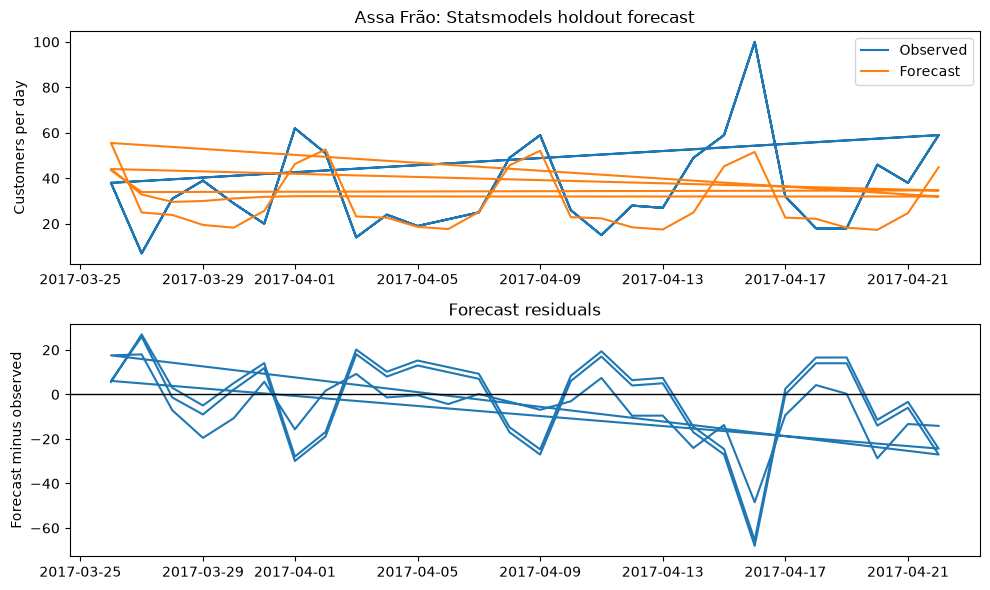

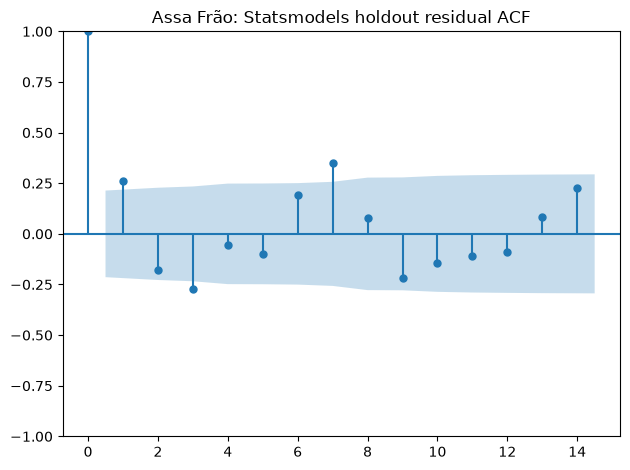

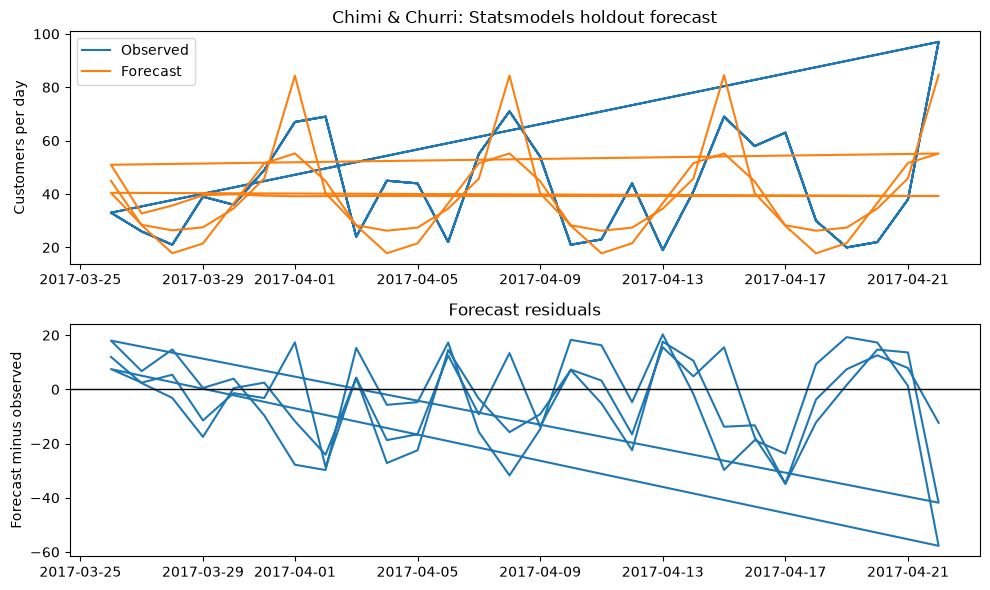

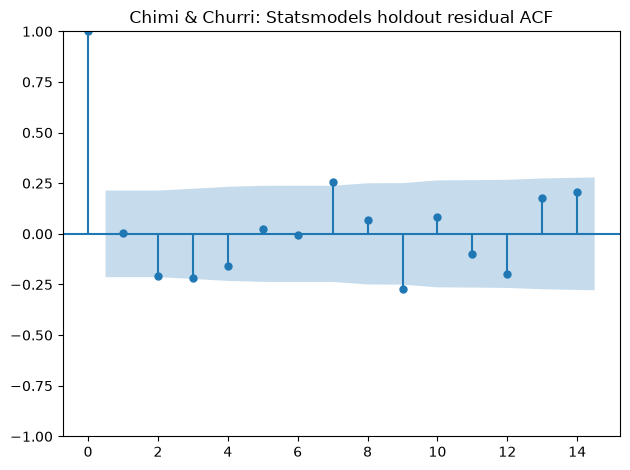

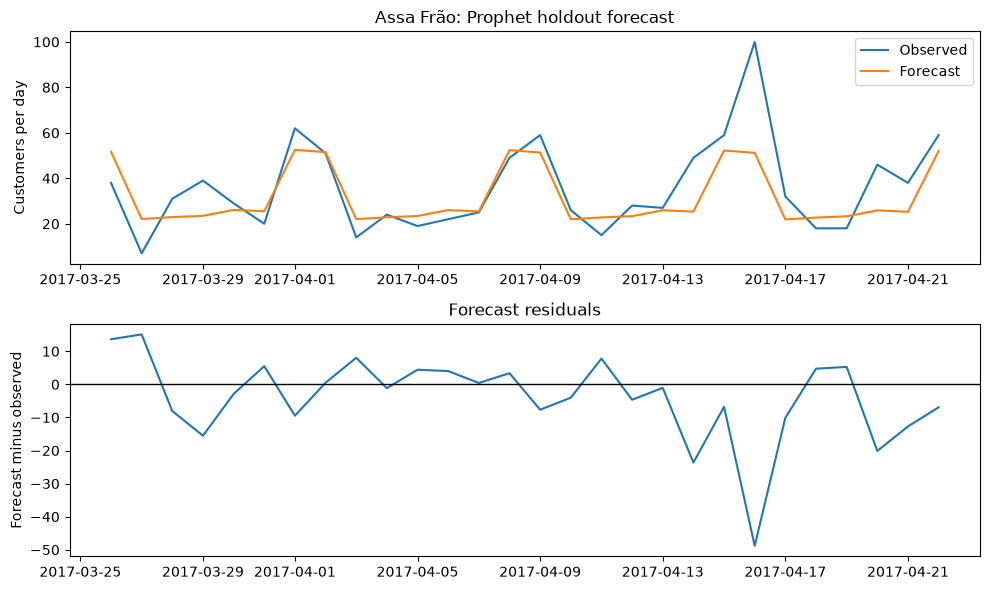

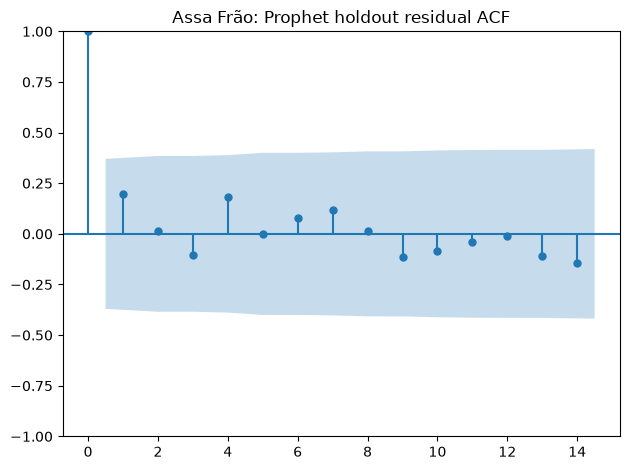

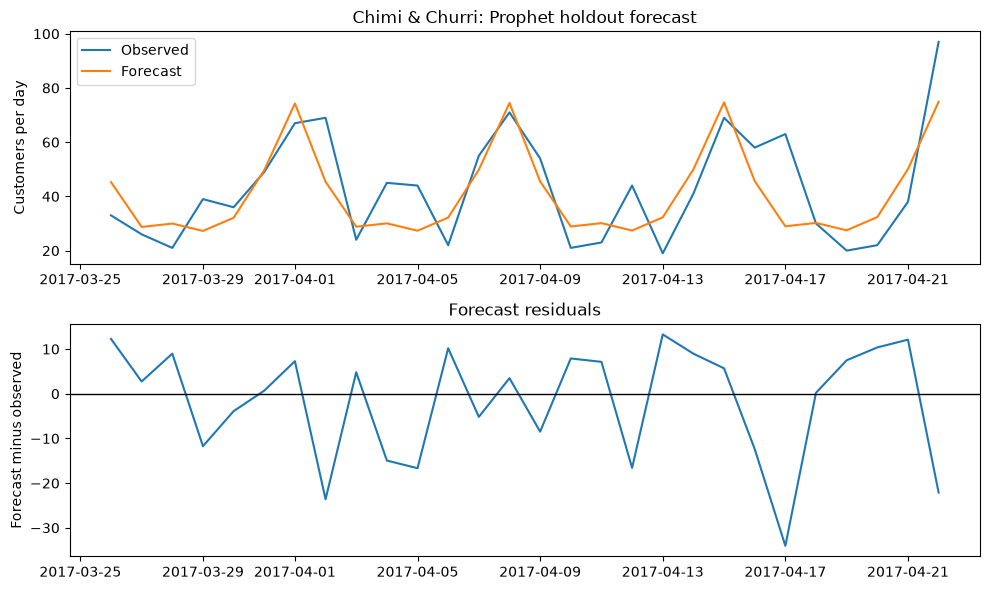

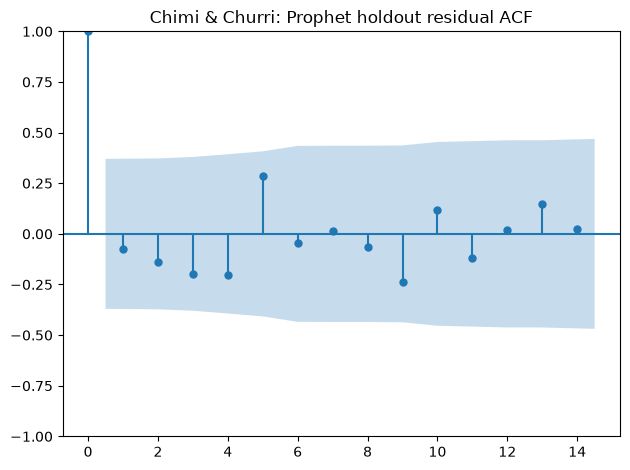

In [1]:
# PROJECT_ROOT_BOOTSTRAP: support kernels started from the repository root or notebooks/.
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Could not locate the project root containing src/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from src.evaluation import interval_metrics

final_metrics = pd.read_csv("reports/final_holdout_metrics.csv")
display(final_metrics.sort_values(["restaurant", "mae"]))

raw = pd.read_csv("data/raw/clientes_restaurantes.csv", parse_dates=["data"], date_format="%m/%d/%Y").set_index("data")
forecasts = {
    "Statsmodels": pd.read_csv("artifacts/forecasts/statsmodels_holdout_forecasts.csv", parse_dates=["date"]),
    "Prophet": pd.read_csv("artifacts/forecasts/prophet_validation_forecasts.csv", parse_dates=["date"]),
}
for model_name, frame in forecasts.items():
    for restaurant, part in frame.groupby("restaurant"):
        actual = raw[restaurant].reindex(part["date"]).to_numpy(dtype=float)
        predicted = part["prediction"].to_numpy(dtype=float)
        residual = predicted - actual
        valid = pd.notna(actual) & pd.notna(predicted)
        print(model_name, restaurant, "residual mean/std:", residual[valid].mean(), residual[valid].std())
        if part["lower"].notna().all() and part["upper"].notna().all():
            print(model_name, restaurant, "holdout interval:", interval_metrics(actual, part["lower"], part["upper"]))
        fig, axes = plt.subplots(2, 1, figsize=(10, 6))
        axes[0].plot(part["date"], actual, label="Observed")
        axes[0].plot(part["date"], predicted, label="Forecast")
        axes[0].set_title(f"{restaurant}: {model_name} holdout forecast")
        axes[0].set_ylabel("Customers per day")
        axes[0].legend()
        axes[1].plot(part["date"][valid], residual[valid])
        axes[1].axhline(0, color="black", linewidth=1)
        axes[1].set_title("Forecast residuals")
        axes[1].set_ylabel("Forecast minus observed")
        plt.tight_layout()
        if valid.sum() > 3:
            plot_acf(residual[valid], lags=min(14, int(valid.sum()) - 2))
            plt.title(f"{restaurant}: {model_name} holdout residual ACF")
            plt.tight_layout()
